
<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/09_Lab_Hopfield.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio: Memorias asociativas con redes de Hopfield

## Objetivo

Construir una red de Hopfield capaz de almacenar imágenes binarias y recuperar una imagen original a partir de una versión con ruido.


# Actividades

Para las imágenes dadas, construya un algoritmo que permita recuperar la imagen original a partir de una imagen perturbada.

Debe implementar funciones para:

1. Convertir una imagen binaria en un vector de estados.
2. Calcular la matriz de pesos de Hopfield.
3. Calcular el campo local que siente una neurona.
4. Actualizar el estado de una neurona.
5. Calcular la energía total de la red.
6. Aplicar ruido a una imagen.
7. Recuperar la imagen mediante actualización asincrónica aleatoria.

---

# Modelo de Hopfield

La matriz de pesos se define mediante la regla de Hebb:

$$
w_{ij}=\frac{1}{N}\sum_{\mu=1}^{P}\xi_i^\mu \xi_j^\mu
$$

con:

$$
w_{ii}=0
$$

donde:

- $N$ es el número total de píxeles,
- $P$ es el número de patrones almacenados,
- $\xi^\mu$ es el patrón $\mu$-ésimo.

---

# Campo local

Para una neurona $i$, el campo local es:

$$
h_i=\sum_j w_{ij}s_j
$$

Este campo representa la influencia colectiva que todas las demás neuronas ejercen sobre la neurona $i$.

---

# Regla de actualización

La actualización determinista de Hopfield es:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

Si:

$$
h_i>0
$$

entonces:

$$
s_i=1
$$

Si:

$$
h_i<0
$$

entonces:

$$
s_i=-1
$$

---

# Energía de la red

La energía total del sistema se define como:

$$
E(s)=-\frac{1}{2}\sum_{ij}w_{ij}s_is_j
$$

o equivalentemente:

$$
E(s)=-\frac{1}{2}s^TWs
$$

El proceso de recuperación debe tender a disminuir la energía.

---

# Algoritmo sugerido

Dada una imagen con ruido:

1. Seleccione aleatoriamente un píxel $i$.
2. Calcule el campo local:

$$
h_i=\sum_j w_{ij}s_j
$$

3. Actualice el estado del píxel:

$$
s_i \leftarrow \mathrm{sign}(h_i)
$$

4. Calcule la nueva energía del sistema:

$$
E(s)=-\frac{1}{2}s^TWs
$$

5. Visite otro píxel aleatoriamente.
6. Repita el proceso hasta que:
   - la imagen deje de cambiar,
   - la energía se estabilice,
   - o se alcance un número máximo de iteraciones.


# Comentario importante

La actualización debe ser preferiblemente **asincrónica y aleatoria**, porque cada vez que se actualiza un píxel, cambia el estado global de la red. Por tanto, el siguiente campo local debe calcularse usando la imagen ya actualizada.

---

# Preguntas guía

1. ¿La energía disminuye durante la recuperación?
2. ¿La red recupera exactamente la imagen original?
3. ¿Qué ocurre si aumenta el nivel de ruido?
4. ¿Qué pasa si se almacenan varias imágenes?
5. ¿Aparecen estados espurios?
6. ¿La recuperación depende del orden en que se actualizan los píxeles?
7. ¿Qué diferencia hay entre actualización sincrónica y asincrónica?

---

# Capacidad de memoria

La capacidad aproximada de una red de Hopfield clásica es:

$$
P_c \approx 0.138N
$$

donde:

- $P_c$ es el número máximo de patrones recuperables,
- $N$ es el número total de neuronas.

Cuando el número de patrones almacenados supera este valor, aparecen errores y estados espurios.




In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def patrones_balanceados(n, m):
    horizontal = -np.ones((n, m))
    horizontal[:n//2, :] = 1

    vertical = -np.ones((n, m))
    vertical[:, :m//2] = 1

    checker = np.indices((n, m)).sum(axis=0)
    checker = np.where(checker % 2 == 0, 1, -1)

    return horizontal, vertical, checker

def agregar_ruido(s, frac=0.25, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido

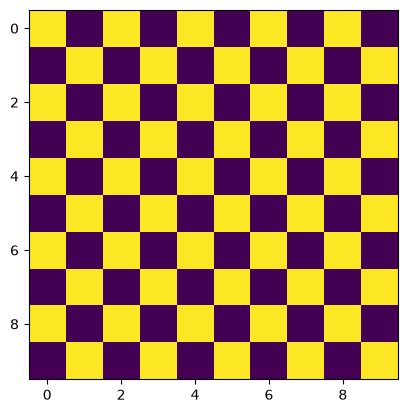

In [3]:
h, v, d = patrones_balanceados(10, 10)
plt.imshow(d)

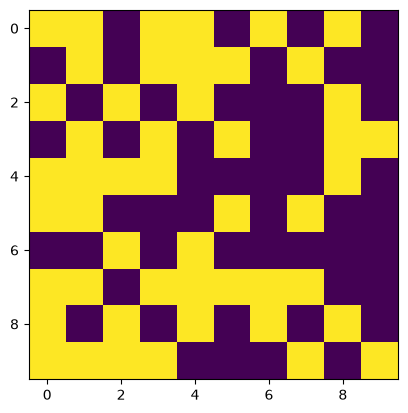

In [4]:
s_ruido = agregar_ruido(np.concat(d), frac=0.25, seed=10)
plt.imshow(np.reshape(s_ruido, (10, 10)))

In [ ]:
n = m = 10
N = n * m
h, v, d = patrones_balanceados(n, m)

psi = np.array([h.flatten(), v.flatten(), d.flatten()])   # (P, N)
P = len(psi)

def pesos(psi):
    N = psi.shape[1]
    W = psi.T @ psi / N          
    np.fill_diagonal(W, 0)      
    return W

W = pesos(psi)
print(W.shape, "simétrica:", np.allclose(W, W.T))

(100, 100) simétrica: True


In [12]:
def campo(W, s):
    return W @ s                        

def actualizar(W, s, i):
    hi = W[i] @ s                       
    return s[i] if hi == 0 else np.sign(hi), hi

def energia(W, s):
    return -0.5 * s @ W @ s

def recuperar(W, s0, max_barridos=30, seed=0):
    rng = np.random.default_rng(seed)
    s = np.asarray(s0, dtype=float).flatten().copy()
    E = energia(W, s)
    hist_E = [E]
    for b in range(max_barridos):
        cambios = 0
        for i in rng.permutation(len(s)):         
            nuevo, hi = actualizar(W, s, i)
            if nuevo != s[i]:
                E += -(nuevo - s[i]) * hi          
                s[i] = nuevo
                cambios += 1
            hist_E.append(E)
        if cambios == 0:                           
            break
    return s, np.array(hist_E)

In [13]:
for nombre, p in [("horizontal", h), ("vertical", v), ("checker", d)]:
    print(f"E({nombre}) = {energia(W, p.flatten()):.3f}")

print("Esperado con patrones ortogonales: -(N-P)/2 =", -(N - P) / 2)
print("¿Son ortogonales?", np.allclose(psi @ psi.T, N * np.eye(P)))

E(horizontal) = -48.500
E(vertical) = -48.500
E(checker) = -48.500
Esperado con patrones ortogonales: -(N-P)/2 = -48.5
¿Son ortogonales? True


horizontal E ruido= -11.04  E final= -48.50  error vs original=0%  energía no creciente=True
vertical   E ruido= -14.40  E final= -48.50  error vs original=0%  energía no creciente=True
checker    E ruido= -14.40  E final= -48.50  error vs original=0%  energía no creciente=True


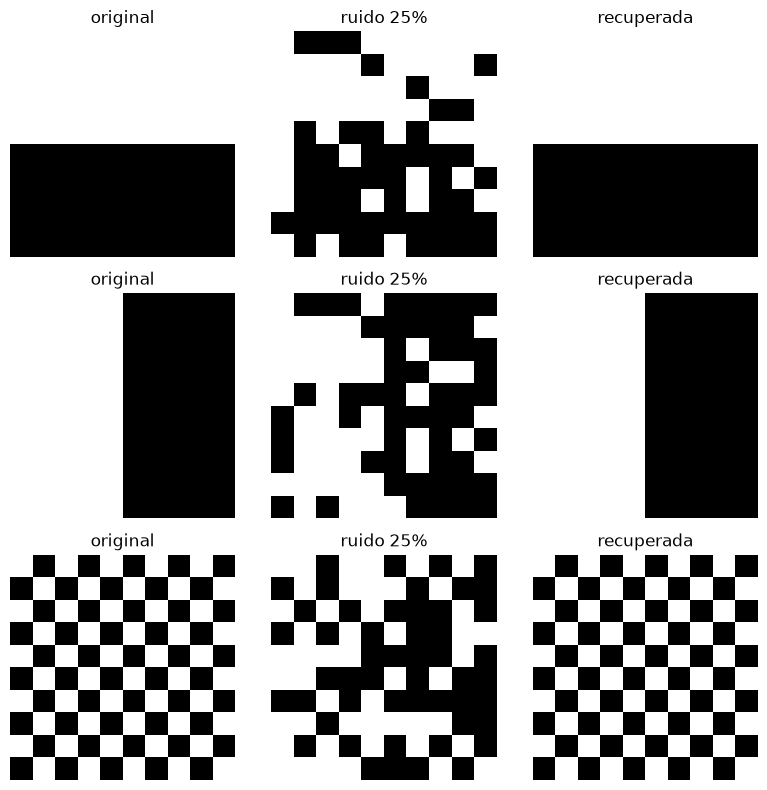

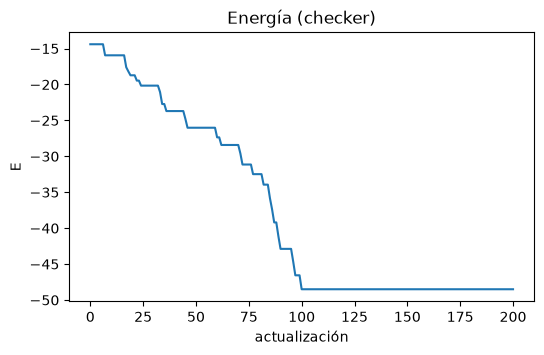

In [14]:
fig, ax = plt.subplots(3, 3, figsize=(8, 8))
for r, (nombre, p) in enumerate([("horizontal", h), ("vertical", v), ("checker", d)]):
    s_ruido = agregar_ruido(p.flatten(), frac=0.25, seed=10)
    s_rec, E_hist = recuperar(W, s_ruido, seed=1)
    print(f"{nombre:10s} E ruido={energia(W, s_ruido):7.2f}  E final={E_hist[-1]:7.2f}  "
          f"error vs original={np.mean(s_rec != p.flatten()):.0%}  "
          f"energía no creciente={np.all(np.diff(E_hist) <= 1e-9)}")
    ax[r, 0].imshow(p, cmap="gray");                      ax[r, 0].set_title("original")
    ax[r, 1].imshow(s_ruido.reshape(n, m), cmap="gray");  ax[r, 1].set_title("ruido 25%")
    ax[r, 2].imshow(s_rec.reshape(n, m), cmap="gray");    ax[r, 2].set_title("recuperada")
    for a in ax[r]: a.axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.5))
plt.plot(E_hist); plt.xlabel("actualización"); plt.ylabel("E"); plt.title("Energía (checker)")
plt.show()

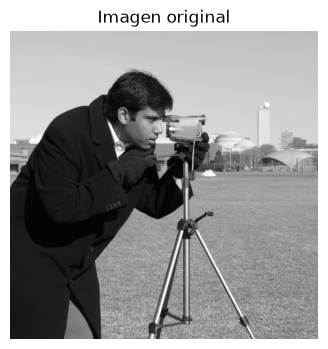

In [5]:
import numpy as np
import matplotlib.pyplot as plt

from skimage import data
from skimage.transform import resize
from skimage.color import rgb2gray

img = data.camera()   # imagen 512x512 en escala de grises

plt.figure(figsize=(4,4))
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")
plt.show()

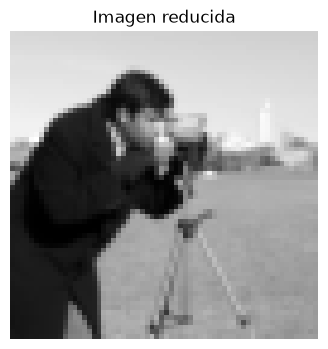

In [6]:
# ============================================================
# Reducir imagen
# ============================================================

n = 64
m = 64

img_small = resize(img, (n, m), anti_aliasing=True)

plt.figure(figsize=(4,4))
plt.imshow(img_small, cmap="gray")
plt.title("Imagen reducida")
plt.axis("off")
plt.show()

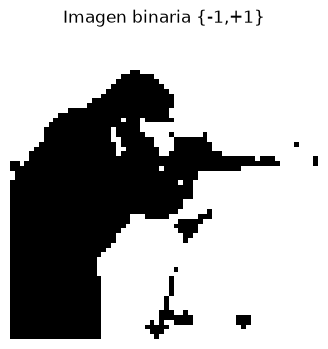

In [7]:
# ============================================================
# Binarización
# ============================================================

threshold = img_small.mean()

img_bin = np.where(img_small > threshold, 1, -1)

plt.figure(figsize=(4,4))
plt.imshow(img_bin, cmap="gray")
plt.title("Imagen binaria {-1,+1}")
plt.axis("off")
plt.show()

In [9]:
# ============================================================
# Ruido
# ============================================================

def agregar_ruido(s, frac=0.30, seed=None):
    if seed is not None:
        np.random.seed(seed)

    s_ruido = s.copy()
    N = len(s)

    n_flip = int(frac * N)
    idx = np.random.choice(N, n_flip, replace=False)

    s_ruido[idx] *= -1

    return s_ruido


frac_ruido = 0.30

s_ruido = agregar_ruido(np.concat(img_bin), frac=frac_ruido, seed=123)


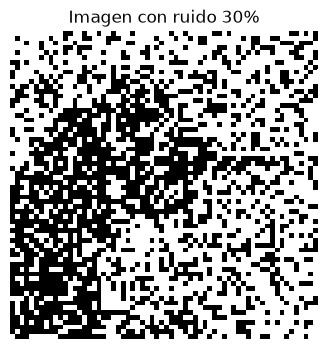

In [10]:
plt.figure(figsize=(4,4))
plt.imshow(s_ruido.reshape(n, m), cmap="gray")
plt.title(f"Imagen con ruido {frac_ruido*100:.0f}%")
plt.axis("off")
plt.show()

E ruido: -327.82   E final: -2047.5
píxeles distintos del original: 0


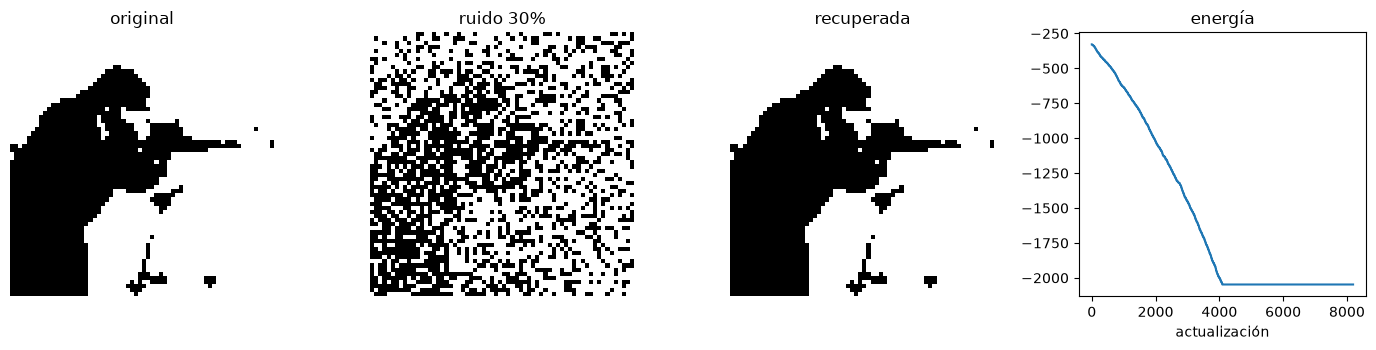

In [15]:
xi = img_bin.flatten().astype(float)
N_img = xi.size
W_img = np.outer(xi, xi) / N_img
np.fill_diagonal(W_img, 0)

s_ruido = agregar_ruido(xi.copy(), frac=0.30, seed=123)
s_rec, E_hist = recuperar(W_img, s_ruido, seed=0)

print("E ruido:", round(energia(W_img, s_ruido), 2), "  E final:", round(E_hist[-1], 2))
print("píxeles distintos del original:", int(np.sum(s_rec != xi)))

fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
for a, im, t in zip(ax[:3], [xi, s_ruido, s_rec], ["original", "ruido 30%", "recuperada"]):
    a.imshow(im.reshape(n_img := 64, 64), cmap="gray"); a.set_title(t); a.axis("off")
ax[3].plot(E_hist); ax[3].set_title("energía"); ax[3].set_xlabel("actualización")
plt.tight_layout(); plt.show()

In [16]:
# Ruido creciente sobre la imagen (preguntas 2 y 3)
for frac in [0.1, 0.3, 0.45, 0.5, 0.55, 0.7]:
    s0 = agregar_ruido(xi.copy(), frac=frac, seed=1)
    sr, _ = recuperar(W_img, s0)
    print(f"ruido {frac:.0%}: error final = {np.mean(sr != xi):.1%}   "
          f"(¿llegó a -xi? {np.array_equal(sr, -xi)})")

ruido 10%: error final = 0.0%   (¿llegó a -xi? False)
ruido 30%: error final = 0.0%   (¿llegó a -xi? False)
ruido 45%: error final = 0.0%   (¿llegó a -xi? False)
ruido 50%: error final = 0.0%   (¿llegó a -xi? False)
ruido 55%: error final = 100.0%   (¿llegó a -xi? True)
ruido 70%: error final = 100.0%   (¿llegó a -xi? True)


In [17]:
# Preguntas 4-5: varios patrones aleatorios en la cuadrícula, N=100 (Pc ≈ 13.8)
rng = np.random.default_rng(0)
print(f"{'P':>3} {'error medio':>12} {'-xi o espurio':>14}")
for P_ in [3, 6, 10, 14, 20, 30]:
    errs = []
    for _ in range(20):
        pat = np.sign(rng.standard_normal((P_, N)))
        Wp = pesos(pat)
        s0 = agregar_ruido(pat[0].copy(), frac=0.1, seed=int(rng.integers(1e6)))
        sr, _ = recuperar(Wp, s0, seed=int(rng.integers(1e6)))
        errs.append(np.mean(sr != pat[0]))
    print(f"{P_:>3} {np.mean(errs):12.3f} {np.mean(np.array(errs) > 0):14.0%}")

# Pregunta 6: dependencia del orden (misma entrada, distintas semillas)
s0 = agregar_ruido(d.flatten(), frac=0.25, seed=10)
finales = [recuperar(W, s0, seed=k)[0] for k in range(20)]
print("¿Todos los órdenes dan el mismo resultado?", all(np.array_equal(finales[0], f) for f in finales))

# Pregunta 7: sincrónica
def recuperar_sinc(W, s0, max_iter=50):
    s = np.asarray(s0, float).flatten().copy()
    Es = [energia(W, s)]
    for _ in range(max_iter):
        nuevo = np.where(W @ s == 0, s, np.sign(W @ s))
        Es.append(energia(W, nuevo))
        if np.array_equal(nuevo, s): break
        s = nuevo
    return s, np.array(Es)

sr, Es = recuperar_sinc(W, agregar_ruido(d.flatten(), 0.45, seed=3))
print("energía sincrónica:", np.round(Es, 1))


  P  error medio  -xi o espurio
  3        0.000             0%
  6        0.000             0%
 10        0.001             5%
 14        0.011            40%
 20        0.100            85%
 30        0.278            95%
¿Todos los órdenes dan el mismo resultado? True
energía sincrónica: [ -0. -36. -36.]


# Laboratorio: Memorias asociativas con redes de Hopfield

## 1. Implementación

Los patrones se aplanan a vectores de estados en {−1, +1} (N = n·m). Se usa la regla de Hebb con w_ii = 0 y actualización asincrónica en orden aleatorio.

`agregar_ruido` es la función dada (voltea una fracción `frac` de píxeles). Para la imagen se almacena un solo patrón: `W = ξξᵀ/N` con diagonal 0.

## 2. Resultados

### Cuadrícula 10×10 (N = 100, P = 3, ruido 25 %)

| Patrón | E ruido | E final | Error vs. original | Energía no creciente |
|---|---|---|---|---|
| horizontal | −11.04 | −48.50 | 0 % | Sí |
| vertical | −14.40 | −48.50 | 0 % | Sí |
| checker | −14.40 | −48.50 | 0 % | Sí |

La energía de cada patrón almacenado es −(N−P)/2 = −48.5. Los tres patrones son ortogonales, y el −P/2 aparece por usar w_ii = 0.

### Imagen del camarógrafo (N = 4096, P = 1, ruido 30 %)

- E ruido = −327.82 y E final = −2047.5 = −(N−1)/2, la energía del patrón almacenado.
- 0 píxeles distintos del original.
- La energía deja de bajar hacia la actualización ≈ 4100: un barrido completo basta. El resto de la curva es el barrido de verificación sin cambios.

### Nivel de ruido (imagen, un patrón)

| Ruido | Error final | ¿Llegó a −ξ? |
|---|---|---|
| 10 % | 0 % | No |
| 30 % | 0 % | No |
| 45 % | 0 % | No |
| 50 % | 0 % | No (indeterminado, ver abajo) |
| 55 % | 100 % | Sí |
| 70 % | 100 % | Sí |

### Varios patrones (cuadrícula, N = 100, patrones aleatorios, 10 % de ruido, 20 ensayos por P)

| P | Error medio | Ensayos con algún error |
|---|---|---|
| 3 | 0.000 | 0 % |
| 6 | 0.000 | 0 % |
| 10 | 0.001 | 5 % |
| 14 | 0.011 | 40 % |
| 20 | 0.100 | 85 % |
| 30 | 0.278 | 95 % |

### Orden de actualización

Con 20 semillas de orden distintas, misma entrada (checker, 25 % de ruido, P = 3): el resultado final fue idéntico en todas.

### Actualización sincrónica (checker, 45 % de ruido, P = 3)

Energías: [−0, −36, −36]. Converge en un paso a un punto fijo con E = −36, mayor que los −48.5 de los patrones almacenados.

## 3. Respuestas a las preguntas guía

1. **¿La energía disminuye?** Sí, y nunca sube (`energía no creciente = True`). Está garantizado porque W es simétrica con diagonal nula y la actualización es asincrónica: cada cambio de un píxel da ΔE = −(s_nuevo − s_viejo)·h_i ≤ 0.

2. **¿Recupera exactamente la imagen?** Sí en los casos probados: 0 % de error con 25 % de ruido en la cuadrícula y 30 % en la cámara, con la energía llegando exactamente a la del patrón almacenado. La recuperación puede fallar con ruido alto o con muchos patrones (puntos 3 y 4).

3. **¿Qué ocurre si aumenta el ruido?** Con un solo patrón, el campo local es h_i = ξ_i(ξ·s − ξ_i s_i)/N, que apunta a ξ si el solape ξ·s es positivo y a −ξ si es negativo. La recuperación es exacta hasta 45 % y pasa a la imagen invertida desde 55 %. El caso de 50 % es indeterminado: con 2048 volteos el solape es exactamente 0, el borde entre las dos cuencas, y el primer píxel visitado decide el destino. El 0 % de error obtenido ahí depende de la semilla y no debe tomarse como robustez.

4. **¿Qué pasa si se almacenan varias imágenes?** La recuperación se degrada por interferencia entre patrones. Con N = 100, P_c ≈ 0.138·N ≈ 13.8, y los resultados concuerdan: error nulo para P ≤ 6, errores ocasionales en P = 10, 40 % de ensayos con error en P = 14 y error medio de 10 % en P = 20. La transición es gradual y no un salto, porque el umbral 0.138·N es asintótico y N = 100 es pequeño. (Los patrones de la cuadrícula, al ser ortogonales, se almacenan sin interferencia; los aleatorios no lo son.)

5. **¿Aparecen estados espurios?** Sí, de dos tipos:
   - El patrón invertido −ξ, que tiene la misma energía que ξ y es un atractor (aparece desde 55 % de ruido).
   - Estados que no son ningún patrón: al sobrepasar la capacidad, los errores aparecen en la mayoría de los ensayos. En la prueba sincrónica, el punto fijo con E = −36 no es un patrón almacenado, y es compatible con una mezcla de patrones; no verifiqué su composición.

6. **¿Depende del orden de actualización?** En el caso probado no: 20 órdenes distintos dieron el mismo resultado. Eso es esperable cuando la entrada está claramente dentro de una cuenca de atracción y la carga es baja. Cerca de las fronteras entre cuencas (como el 50 % de ruido) o con muchos patrones, el orden sí puede decidir el atractor final.

7. **Sincrónica vs. asincrónica.** En la asincrónica cada campo local usa el estado ya actualizado, y eso garantiza que la energía no suba. En la sincrónica todas las neuronas se actualizan a la vez con el estado anterior, y esa garantía se pierde: puede haber oscilaciones de periodo 2, y aquí terminó en un estado espurio (E = −36) en un solo paso. Con una sola entrada no se puede decir que la sincrónica sea peor en general, pero en este caso no recuperó el patrón. (Además, el ruido usado fue 45 % y no 25 %, así que no es una comparación con la prueba asincrónica de la cuadrícula.)

## 4. Conclusiones

- La regla de Hebb con actualización asincrónica aleatoria define una función de energía que solo baja, y los patrones almacenados son sus mínimos.
- Con pocos patrones y ruido moderado la recuperación es exacta; el límite para un patrón es el 50 % de ruido.
- La capacidad práctica coincide con P_c ≈ 0.138·N (≈ 14 patrones con N = 100); por encima de ese valor aparecen errores y estados espurios.
- La actualización asincrónica es la que da las garantías de convergencia del modelo.